# 01 – Khám phá và làm sạch dữ liệu LaDe-D Jilin

**Mục tiêu.** Mô tả tập `delivery_jl.csv`, kiểm tra chất lượng, áp dụng quy tắc làm sạch có truy vết, đánh giá độ ổn định phạm vi lấy mẫu để xác định cửa sổ thực nghiệm, và chọn mức tổng hợp nhu cầu cho bài toán dự báo.

**Nguồn.** LaDe (Wu và cs., arXiv:2306.10675v3), tập con LaDe-D, thành phố Jilin. Định nghĩa các cột theo Table 8 của bài báo.

**Hai quy ước được dùng xuyên suốt.**
1. Dữ liệu chỉ ghi `MM-DD hh:mm:ss`, không có năm. Datasheet chỉ nêu dữ liệu được trích từ tháng 5 đến tháng 11 của một năm gần đây, nên năm 2022 là quy ước kỹ thuật. Chỉ các đặc trưng thứ trong tuần và cuối tuần phụ thuộc quy ước này; chúng không phải kết quả đã xác minh.
2. Mục 2 chứng minh `ds` trùng với ngày tiếp nhận đơn. Biến mục tiêu vì vậy là số đơn được tiếp nhận theo ngày, không phải số đơn hoàn thành trong ngày.

In [1]:
import sys, json
from pathlib import Path
root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))  # repository root, so that `src` is importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src import config

from src import preprocessing
from src.data_loader import loadRawDelivery, loadAnalysisOrders, loadDemandPanel
from src.preprocessing import addDerivedColumns, haversineMeters, dailyActivity, findMeanShifts, segmentDaily, selectStableWindow
from src.visualization import saveFigure

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

raw = loadRawDelivery()
df = addDerivedColumns(raw)  # all 31,415 raw rows with derived columns and quality flags
print(f"rows={len(df):,}  raw columns={raw.shape[1]}  derived columns added={df.shape[1] - raw.shape[1]}")

rows=31,415  raw columns=17  derived columns added=17


## 1. Tổng quan và đối chiếu với bài báo

In [2]:
display(raw.head(3).T)
courierDay = df.groupby(["courier_id", "ds"]).size()
ref = config.PAPER_JILIN_STATS
comparison = pd.DataFrame({
    "paper (Table 12)": [ref["couriers"], ref["packages"], ref["avgEtaMinutes"], ref["avgPackagePerCourierDay"]],
    "this file": [df["courier_id"].nunique(), len(df), round(df["delivery_minutes"].mean(), 1), round(courierDay.mean(), 1)],
}, index=["couriers", "packages (paper rounds to 31k)", "mean delivery time (min)", "mean packages / courier / day"])
display(comparison)
print("accept dates:", df["accept_dt"].min(), "->", df["accept_dt"].max())
print("distinct days with orders:", df[config.DEMAND_DATE_COLUMN].nunique(),
      "| calendar span (days):", (df[config.DEMAND_DATE_COLUMN].max() - df[config.DEMAND_DATE_COLUMN].min()).days + 1)

,0,1,2
order_id,3322376,4093119,36226
region_id,31,31,31
city,Jilin,Jilin,Jilin
courier_id,4849,4849,4849
lng,126.56526,126.56519,126.56987
lat,43.84112,43.8411,43.85017
aoi_id,94,94,235
aoi_type,14,14,14
accept_time,09-25 08:08:00,08-21 09:11:00,06-08 15:42:00
accept_gps_time,09-25 08:08:00,08-21 09:11:00,06-08 15:42:00


,paper (Table 12),this file
couriers,57.0,57.0
packages (paper rounds to 31k),31000.0,31415.0
mean delivery time (min),203.0,203.5
mean packages / courier / day,16.2,16.3


accept dates: 2022-05-12 09:28:00 -> 2022-10-28 08:54:00
distinct days with orders: 163 | calendar span (days): 170


## 2. Chất lượng dữ liệu

In [3]:
nullTable = raw.isna().sum().to_frame("nullCount").assign(pct=lambda t: (t.nullCount / len(raw) * 100).round(2))
display(nullTable[nullTable.nullCount > 0])
print("duplicate order_id:", raw["order_id"].duplicated().sum(), "| fully duplicated rows:", raw.duplicated().sum())
print("city values:", list(raw["city"].unique()))
print("accept_time == accept_gps_time in every row:", (raw["accept_time"] == raw["accept_gps_time"]).all())
print("delivery_time == delivery_gps_time in every row:", (raw["delivery_time"] == raw["delivery_gps_time"]).all())
flagCols = [c for c in df.columns if c.startswith("flag_")]
display(df[flagCols].sum().to_frame("rowsFlagged"))

,nullCount,pct
accept_gps_lng,955,3.04
accept_gps_lat,955,3.04


duplicate order_id: 0 | fully duplicated rows: 0
city values: ['Jilin']
accept_time == accept_gps_time in every row: True
delivery_time == delivery_gps_time in every row: True


,rowsFlagged
flag_parse_error,0
flag_negative_duration,0
flag_zero_duration,50
flag_missing_accept_gps,955
flag_ds_ne_accept_date,0
flag_ds_ne_delivery_date,19
flag_invalid_gps,10


In [4]:
# Meaning of `ds`: the paper's Table 8 describes it as the delivery date; compare with both timestamps.
print("ds == accept date  :", (~df["flag_ds_ne_accept_date"]).mean())
print("ds == delivery date:", (~df["flag_ds_ne_delivery_date"]).mean(),
      "| rows where it differs:", int(df["flag_ds_ne_delivery_date"].sum()))
print("orders delivered on a later calendar day than accepted:", int((df["delivery_date"] > df["accept_date"]).sum()))
display(df.loc[df["flag_ds_ne_delivery_date"], ["accept_time", "delivery_time", "ds"]].head(5))

ds == accept date  : 1.0
ds == delivery date: 0.9993951933789591 | rows where it differs: 19
orders delivered on a later calendar day than accepted: 19


,accept_time,delivery_time,ds
14113,05-29 08:33:00,05-30 04:59:00,0529
19290,05-16 11:00:00,05-17 05:03:00,0516
19765,07-28 08:34:00,07-30 09:42:00,0728
20427,08-28 07:42:00,08-29 08:10:00,0828
20479,06-18 14:45:00,06-19 16:22:00,0618


,delivery_minutes
count,31415.0
mean,203.5
std,142.7
min,0.0
1%,7.0
5%,35.0
25%,99.0
50%,175.0
75%,276.0
95%,469.0


IQR upper fence = 542 min -> rows above: 930 (3.0%)
rows > 12 h: 115 | rows > 24 h: 8 | rows == 0 min: 50


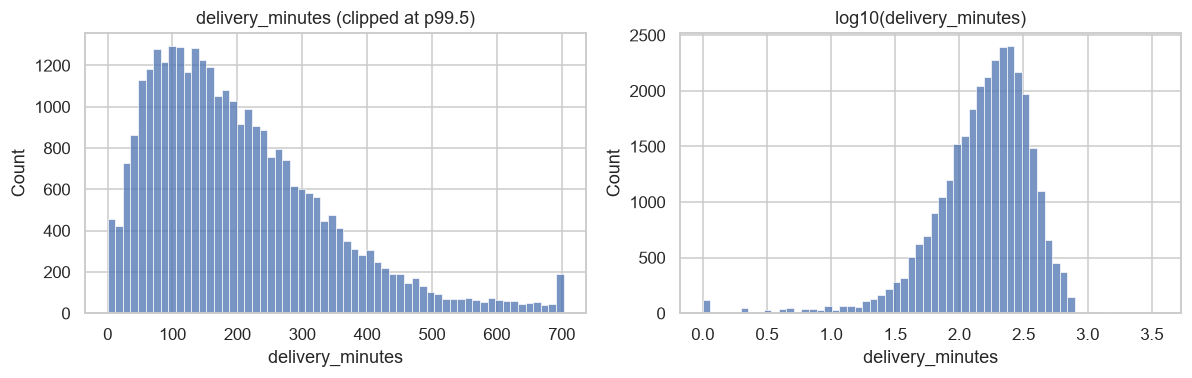

In [5]:
# Delivery duration: distribution and outlier rule
m = df["delivery_minutes"]
display(m.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).round(1).to_frame("delivery_minutes"))
q1, q3 = m.quantile([.25, .75])
iqrFence = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence = {iqrFence:.0f} min -> rows above: {(m > iqrFence).sum()} ({(m > iqrFence).mean():.1%})")
print(f"rows > 12 h: {(m > 720).sum()} | rows > 24 h: {(m > 1440).sum()} | rows == 0 min: {(m == 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(m.clip(upper=m.quantile(.995)), bins=60, ax=ax[0]); ax[0].set_title("delivery_minutes (clipped at p99.5)")
sns.histplot(np.log10(m.clip(lower=1)), bins=60, ax=ax[1]); ax[1].set_title("log10(delivery_minutes)")
saveFigure("duration_distribution")

In [6]:
# Missing accept GPS: random or concentrated?
miss = df["flag_missing_accept_gps"]
print("% missing by region:\n", df.groupby("region_id")["flag_missing_accept_gps"].mean().mul(100).round(2).to_string())
print("\n% missing by month:\n", df.groupby(df["accept_dt"].dt.month)["flag_missing_accept_gps"].mean().mul(100).round(2).to_string())
byCourier = df.groupby("courier_id")["flag_missing_accept_gps"].agg(["mean", "sum"]).sort_values("sum", ascending=False)
display(byCourier.head(5))
print("share of all missing rows held by the 5 couriers above:", round(byCourier["sum"].head(5).sum() / miss.sum(), 3))

% missing by region:
 region_id
31      2.08
53      0.27
129     0.00
165    20.79

% missing by month:
 accept_dt
5     9.83
6     8.80
7     1.65
8     0.13
9     1.20
10    2.48


,mean,sum
courier_id,,
3156,0.371000,371
1656,0.137931,284
435,0.055686,119
2709,0.278125,89
949,0.013458,36


share of all missing rows held by the 5 couriers above: 0.941


In [7]:
# Coordinate sanity: distance of every stop from the median centre (paper: spatial span about 20 km x 20 km)
cLng, cLat = df["lng"].median(), df["lat"].median()
dist = haversineMeters(df["lng"], df["lat"], cLng, cLat) / 1000
print(pd.Series(dist).describe().round(2).to_string())
print(f"stops farther than {config.FAR_STOP_KM} km from the centre:", int((dist > config.FAR_STOP_KM).sum()))
valid = df.loc[~df["flag_invalid_gps"]]
for c in ["accept_gps_lng", "accept_gps_lat", "delivery_gps_lng", "delivery_gps_lat"]:
    print(c, "(valid rows) min/max:", valid[c].min(), valid[c].max())

count    31415.00
mean         3.44
std          2.44
min          0.33
25%          1.84
50%          2.85
75%          4.00
max         44.11
stops farther than 20 km from the centre: 43
accept_gps_lng (valid rows) min/max: 126.47652 126.62885
accept_gps_lat (valid rows) min/max: 43.7752 43.94521
delivery_gps_lng (valid rows) min/max: 125.3551 126.67634
delivery_gps_lat (valid rows) min/max: 42.53939 43.99768


## 3. Quy tắc làm sạch và tập phân tích

Các quy tắc được cài trong `src/preprocessing.py` và không sửa file gốc.

| Quy tắc | Xử lý | Lý do |
|---|---|---|
| Toạ độ GPS gần (0, 0) | Chuyển thành giá trị thiếu | Giá trị giữ chỗ của thiết bị, ngoài khu vực Jilin |
| Đơn có thời lượng giao > 24 giờ | Loại khỏi tập phân tích, giữ trong tập có cờ và nhật ký `excluded_rows.csv` | Ngoại lệ cực đoan (tối đa 3.573 phút); không thể là một lần giao thông thường |
| Thiếu `accept_gps` | Giữ, gắn cờ | Thiếu tập trung ở vài shipper, không ảnh hưởng đến đếm đơn |
| Thời lượng bằng 0 phút | Giữ, gắn cờ | Có thể là làm tròn phút; không ảnh hưởng đến đếm đơn |
| Điểm dừng xa tâm | Không lọc | Bán kính từ tâm không phải ranh giới AOI |

Quy tắc loại đơn > 24 giờ dùng kết quả giao hàng, là thông tin chỉ biết sau khi đơn hoàn thành. Dự báo trong các notebook sau vì vậy áp dụng cho tập phân tích đã lọc.

In [8]:
preprocessing.main()  # raw -> flagged / analysis / exclusion log / demand tables / experimental window
flagged = pd.read_parquet(config.FLAGGED_FILE)
orders = loadAnalysisOrders()
excluded = pd.read_csv(config.EXCLUDED_LOG_FILE)
display(excluded)
assert len(flagged) == len(orders) + len(excluded) and flagged.order_id.is_unique
display(flagged[["flag_invalid_gps", "flag_missing_accept_gps", "flag_zero_duration", "flag_exclude_over_24h"]].sum().to_frame("rows"))
print(f"raw/flagged rows: {len(flagged):,} | analysis rows: {len(orders):,} | excluded: {len(excluded)}")

raw=31,415 analysis=31,407 excluded=8 series=41 aois=1259 window=2022-06-27..2022-10-02


,order_id,delivery_minutes,reason
0,1249828,2948.0,delivery_minutes>1440
1,3733224,1468.0,delivery_minutes>1440
2,1279740,1537.0,delivery_minutes>1440
3,331475,1477.0,delivery_minutes>1440
4,1969323,1453.0,delivery_minutes>1440
5,3881643,2093.0,delivery_minutes>1440
6,3321484,1641.0,delivery_minutes>1440
7,420775,3573.0,delivery_minutes>1440


,rows
flag_invalid_gps,10
flag_missing_accept_gps,955
flag_zero_duration,50
flag_exclude_over_24h,8


raw/flagged rows: 31,415 | analysis rows: 31,407 | excluded: 8


## 4. Phân phối đơn hàng (tập phân tích)

days with zero orders inside the span: 7 of 170


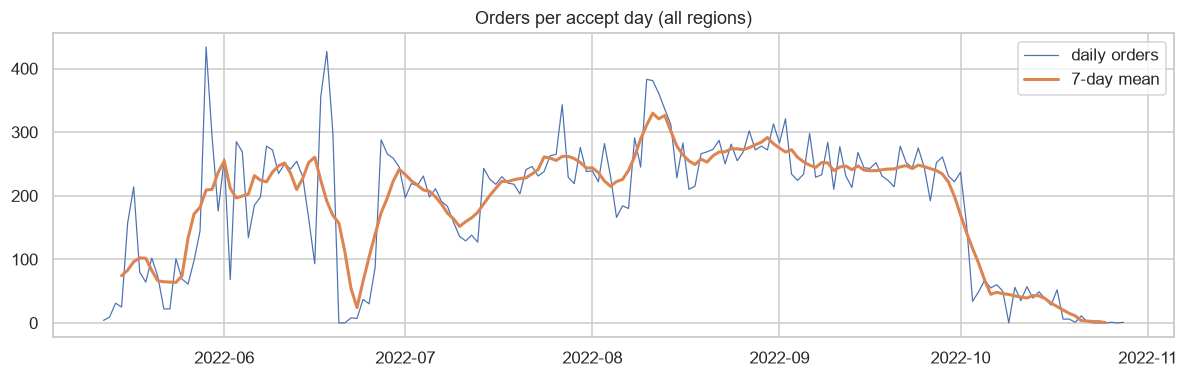

region_id,31,53,129,165,total,meanPerDay
month,,,,,,
5,980,544,180,474,2178,108.9
6,1757,1692,1578,698,5725,190.8
7,1646,2368,1937,730,6681,215.5
8,1972,3042,2495,827,8336,268.9
9,2087,2583,2030,698,7398,246.6
10,376,136,425,152,1089,38.9


In [9]:
dateCol = config.DEMAND_DATE_COLUMN
daily = dailyActivity(orders)
print("days with zero orders inside the span:", int((daily["orders"] == 0).sum()), "of", len(daily))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily.index, daily["orders"], lw=.8, label="daily orders")
ax.plot(daily.index, daily["orders"].rolling(7, center=True).mean(), lw=2, label="7-day mean")
ax.set_title("Orders per accept day (all regions)"); ax.legend()
saveFigure("daily_orders")

monthly = orders.groupby([orders[dateCol].dt.month.rename("month"), "region_id"]).size().unstack(fill_value=0)
monthly["total"] = monthly.sum(axis=1)
monthly["meanPerDay"] = daily["orders"].groupby(daily.index.month).mean().round(1)
display(monthly)

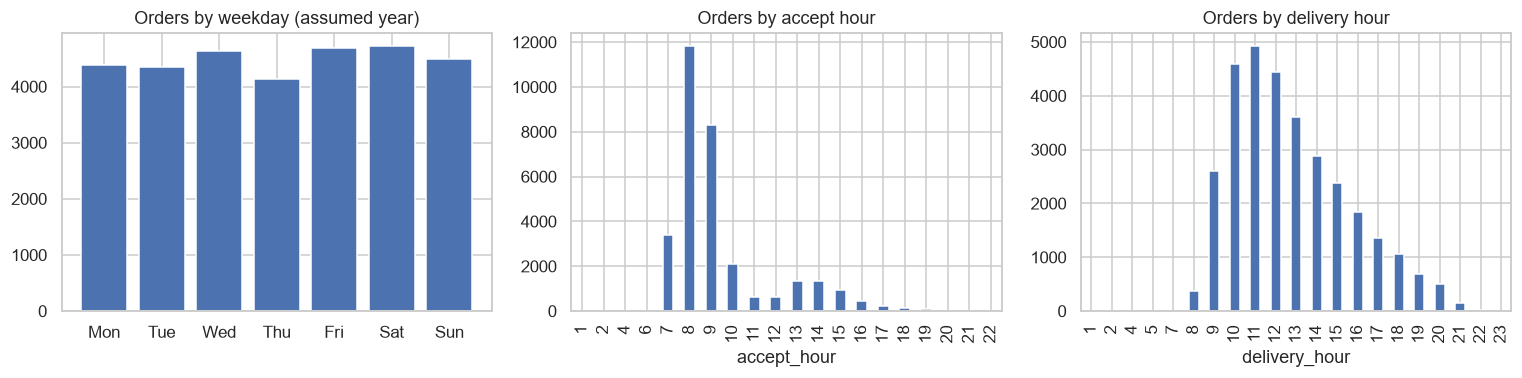

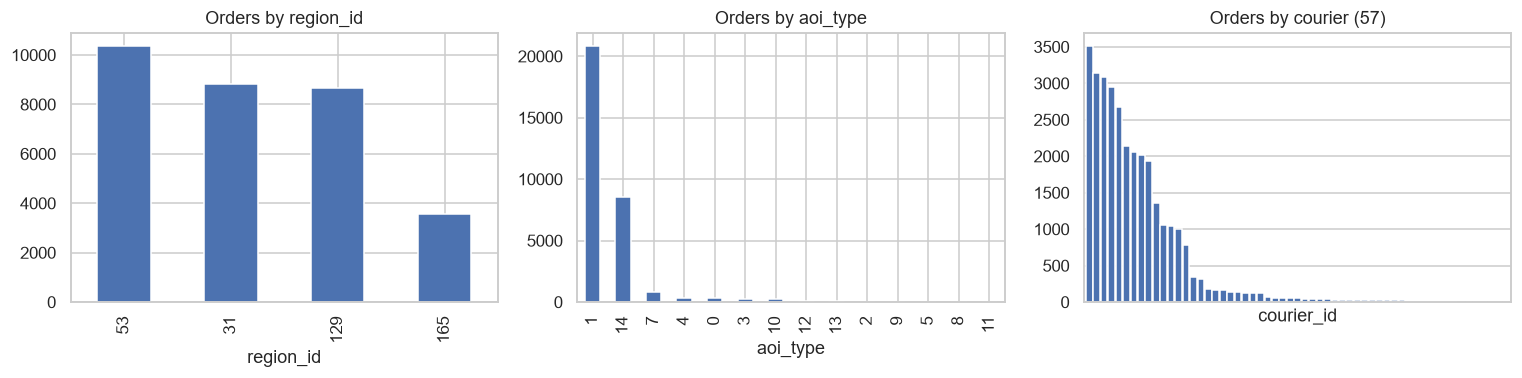

aoi_type share (%):
 aoi_type
1     66.3
14    27.1
7      2.6
4      1.0
0      0.9
3      0.7
10     0.7
12     0.3


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
dow = orders.groupby("day_of_week").size().reindex(range(7), fill_value=0)
ax[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values); ax[0].set_title("Orders by weekday (assumed year)")
orders["accept_hour"].value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Orders by accept hour")
orders["delivery_hour"].value_counts().sort_index().plot.bar(ax=ax[2]); ax[2].set_title("Orders by delivery hour")
saveFigure("weekday_hour")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
orders["region_id"].value_counts().plot.bar(ax=ax[0]); ax[0].set_title("Orders by region_id")
orders["aoi_type"].value_counts().plot.bar(ax=ax[1]); ax[1].set_title("Orders by aoi_type")
orders["courier_id"].value_counts().plot.bar(ax=ax[2], width=.9); ax[2].set_title("Orders by courier (57)"); ax[2].set_xticks([])
saveFigure("region_aoitype_courier")
print("aoi_type share (%):\n", (orders["aoi_type"].value_counts(normalize=True) * 100).round(1).head(8).to_string())

## 5. Độ ổn định phạm vi lấy mẫu và cửa sổ thực nghiệm

Bài báo cho biết dữ liệu chỉ gồm các shipper được lấy mẫu. Vì $\text{orders} = \text{activeCouriers} \times \text{ordersPerCourier}$, số đơn giảm do ít shipper hoạt động phản ánh thay đổi *ai được quan sát*, còn đơn/shipper giảm phản ánh khối lượng công việc hoặc nhu cầu. Phân đoạn nhị phân theo thay đổi trung bình được dùng để tìm điểm gãy; giai đoạn dài nhất có số shipper hoạt động ổn định là cửa sổ thực nghiệm chính, toàn kỳ được giữ cho phân tích độ nhạy.

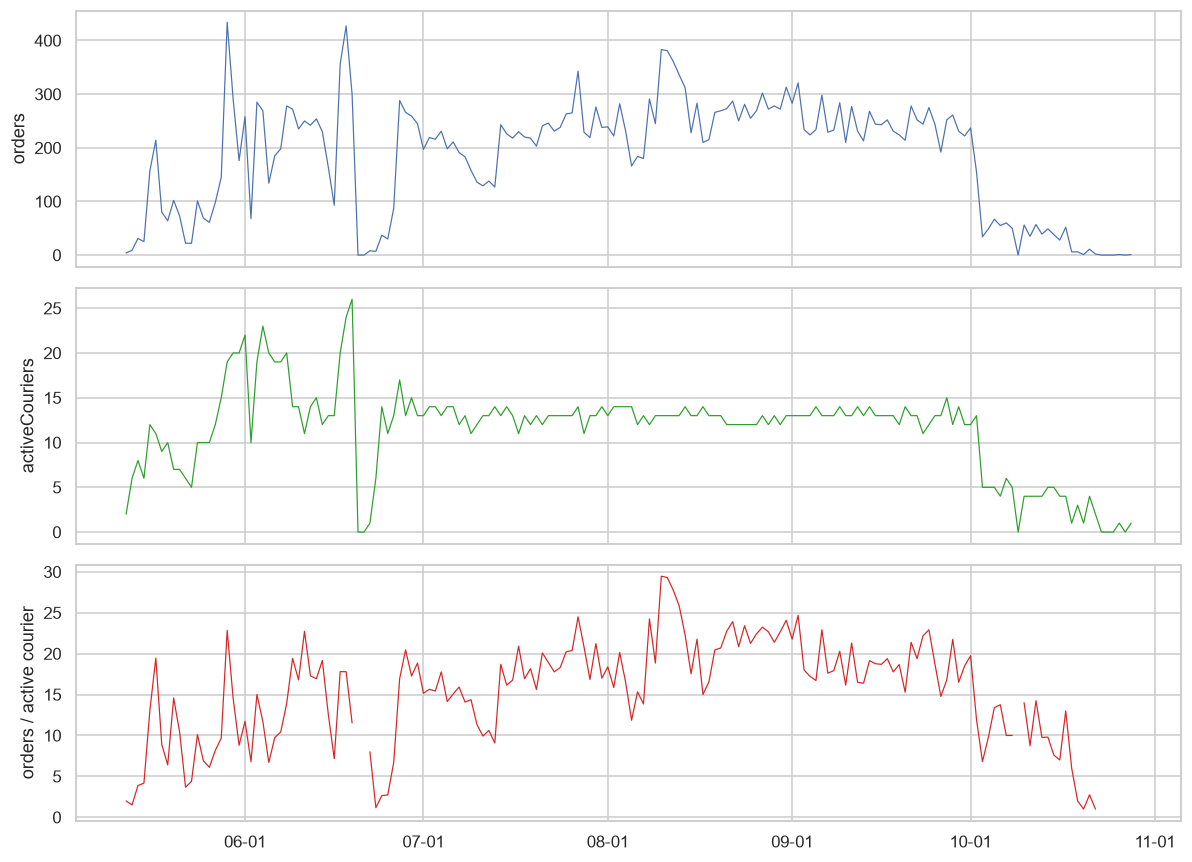

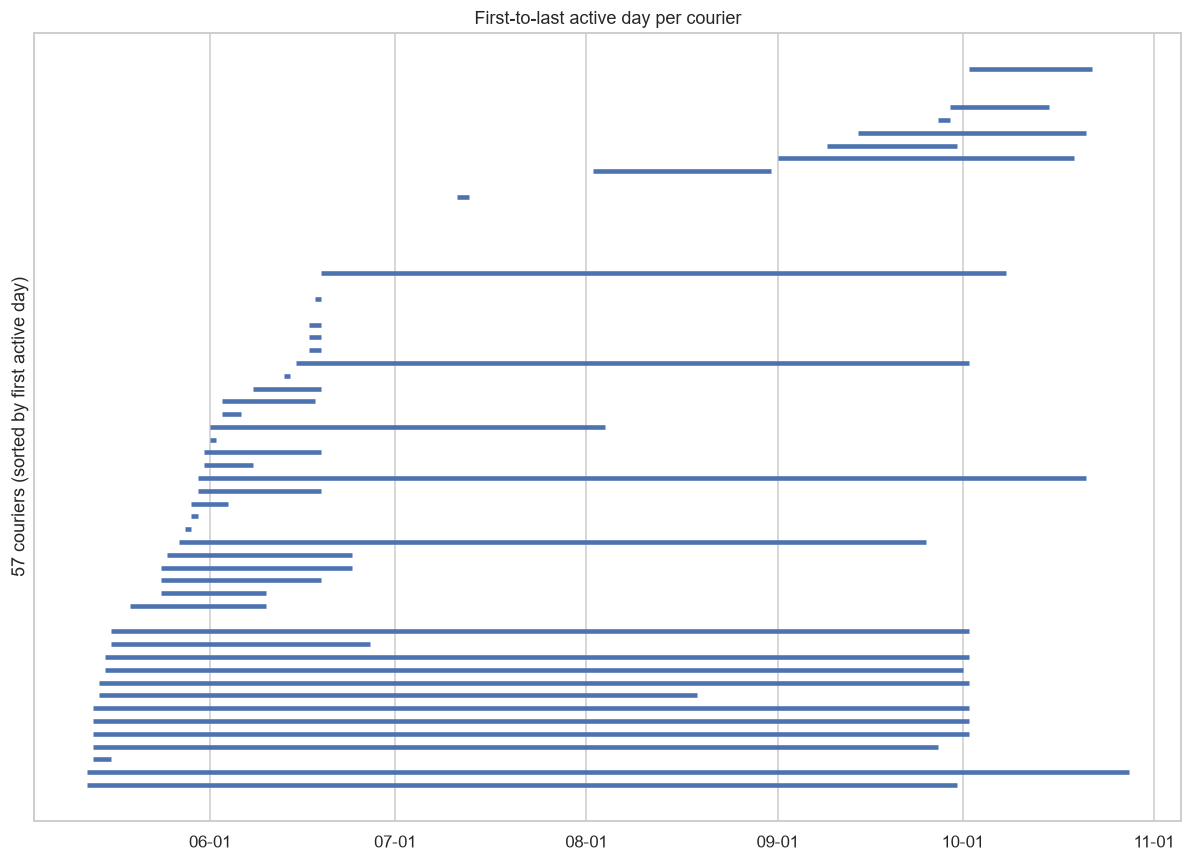

couriers whose last active day is in October: 17
last
2022-09-25    1
2022-09-27    1
2022-09-29    1
2022-09-30    2
2022-10-01    2
2022-10-02    8
2022-10-08    1
2022-10-15    1
2022-10-19    1
2022-10-21    2
2022-10-22    1
2022-10-28    1


In [11]:
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(daily.index, daily["orders"], lw=.8); ax[0].set_ylabel("orders")
ax[1].plot(daily.index, daily["activeCouriers"], lw=.8, color="tab:green"); ax[1].set_ylabel("activeCouriers")
ax[2].plot(daily.index, daily["ordersPerCourier"], lw=.8, color="tab:red"); ax[2].set_ylabel("orders / active courier")
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
saveFigure("stability_daily_activity")

span = orders.groupby("courier_id").agg(first=(dateCol, "min"), last=(dateCol, "max")).sort_values(["first", "last"]).reset_index()
fig, ax = plt.subplots(figsize=(11, 8))
ax.hlines(y=range(len(span)), xmin=span["first"], xmax=span["last"], lw=3)
ax.set_yticks([]); ax.set_ylabel("57 couriers (sorted by first active day)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d")); ax.set_title("First-to-last active day per courier")
saveFigure("stability_courier_spans")
print("couriers whose last active day is in October:", int((span["last"] >= "2022-10-01").sum()))
print(span["last"].value_counts().sort_index().loc["2022-09-25":].to_string())

break dates, active couriers: ['2022-05-27', '2022-06-20', '2022-06-27', '2022-10-03']
break dates, orders         : ['2022-05-29', '2022-06-20', '2022-06-27', '2022-07-21', '2022-10-03']


,start,end,days,meanOrders,meanActiveCouriers,meanOrdersPerCourier
0,2022-05-12,2022-05-26,15,68.9,7.9,7.7
1,2022-05-27,2022-06-19,24,235.1,17.2,13.7
2,2022-06-20,2022-06-26,7,24.1,6.4,4.2
3,2022-06-27,2022-10-02,98,243.5,13.0,18.8
4,2022-10-03,2022-10-28,26,26.8,3.0,7.7


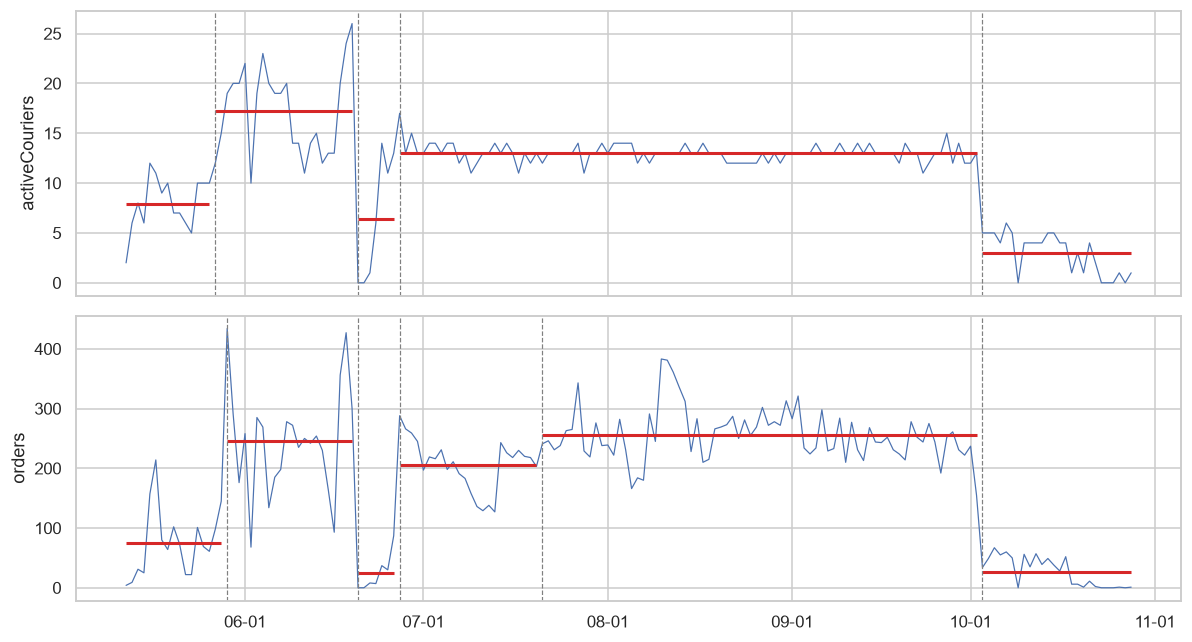

In [12]:
def segmentTable(frame, breaks):
    rows = []
    for a, b in segmentDaily(frame, breaks):
        seg = frame.iloc[a:b]
        rows.append({"start": seg.index[0].date(), "end": seg.index[-1].date(), "days": b - a,
                     "meanOrders": seg["orders"].mean().round(1), "meanActiveCouriers": seg["activeCouriers"].mean().round(1),
                     "meanOrdersPerCourier": seg["ordersPerCourier"].mean().round(1)})
    return pd.DataFrame(rows)

breaksCouriers = findMeanShifts(daily["activeCouriers"].values, maxBreaks=5, minSegment=7)
breaksOrders = findMeanShifts(daily["orders"].values, maxBreaks=5, minSegment=7)
print("break dates, active couriers:", [str(daily.index[k].date()) for k in breaksCouriers])
print("break dates, orders         :", [str(daily.index[k].date()) for k in breaksOrders])
segments = segmentTable(daily, breaksCouriers)
display(segments)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for a, col, br in ((ax[0], "activeCouriers", breaksCouriers), (ax[1], "orders", breaksOrders)):
    a.plot(daily.index, daily[col], lw=.8)
    for s, e in segmentDaily(daily, br):
        a.hlines(daily[col].iloc[s:e].mean(), daily.index[s], daily.index[e - 1], color="tab:red", lw=2)
    for k in br:
        a.axvline(daily.index[k], color="gray", ls="--", lw=.8)
    a.set_ylabel(col)
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
saveFigure("stability_breakpoints")

In [13]:
# Decompose the drop between the stable plateau and the tail into couriers and orders per courier
longest = segments.sort_values("days", ascending=False).iloc[0]
plateau = (pd.Timestamp(longest["start"]), pd.Timestamp(longest["end"]))
base = daily.loc[plateau[0]:plateau[1]]
tail = daily.loc[plateau[1] + pd.Timedelta(days=1):]
print("plateau:", plateau[0].date(), "->", plateau[1].date(), f"({len(base)} days) | tail:", tail.index[0].date(), "->", tail.index[-1].date(), f"({len(tail)} days)")
from src.preprocessing import decomposeActivityChange
decomposition = decomposeActivityChange(base, tail)
o = decomposition['order_log_ratio']
c = decomposition['courier_log_ratio']
p = decomposition['productivity_log_ratio']
assert np.isclose(o, c + p), 'log-ratio decomposition must balance'
print(f"ln(orders ratio) = {o:.4f} = ln(couriers ratio) {c:.4f} + ln(weighted productivity ratio) {p:.4f}")
share = decomposition['courier_log_share']
print('courier component / observed log change:', f'{share:.1%}' if share is not None else 'undefined (no mean order change)')
print('Productivity = total orders / total active courier-days in each period.')
print('Descriptive accounting identity; no causal attribution or inference of city-wide demand.')

# Cohort: couriers active in the last 14 days of the plateau
lastWeeks = orders[(orders[dateCol] > plateau[1] - pd.Timedelta(days=14)) & (orders[dateCol] <= plateau[1])]
cohort = set(lastWeeks["courier_id"])
inTail = orders[(orders[dateCol] > plateau[1]) & orders["courier_id"].isin(cohort)]
perDay = lambda f: f.groupby(["courier_id", dateCol]).size().mean()
print("cohort size:", len(cohort), "| still active in the tail:", inTail["courier_id"].nunique())
print("orders per cohort courier-day: last 14 plateau days =", round(perDay(lastWeeks), 1), "| tail =", round(perDay(inTail), 1))
last = orders.groupby("courier_id")[dateCol].max()
print("couriers whose last active day is within 1 day of the plateau end:",
      int(((last >= plateau[1] - pd.Timedelta(days=1)) & (last <= plateau[1] + pd.Timedelta(days=1))).sum()))
print("\nInterruption around 20-26 June:")
display(daily.loc["2022-06-16":"2022-06-28"])

plateau: 2022-06-27 -> 2022-10-02 (98 days) | tail: 2022-10-03 -> 2022-10-28 (26 days)
ln(orders ratio) = 2.2065 = ln(couriers ratio) 1.4800 + ln(weighted productivity ratio) 0.7265
courier component / observed log change: 67.1%
Productivity = total orders / total active courier-days in each period.
Descriptive accounting identity; no causal attribution or inference of city-wide demand.
cohort size: 21 | still active in the tail: 6
orders per cohort courier-day: last 14 plateau days = 18.3 | tail = 7.9
couriers whose last active day is within 1 day of the plateau end: 10

Interruption around 20-26 June:


,orders,activeCouriers,ordersPerCourier
ds_date,,,
2022-06-16,93,13,7.153846
2022-06-17,356,20,17.800000
2022-06-18,427,24,17.791667
2022-06-19,300,26,11.538462
2022-06-20,0,0,NaN
2022-06-21,0,0,NaN
2022-06-22,8,1,8.000000
2022-06-23,7,6,1.166667
2022-06-24,37,14,2.642857


In [14]:
# The window written by src.preprocessing must equal the one derived here
window = json.loads(config.STABLE_PERIOD_FILE.read_text(encoding="utf-8"))
assert (window["start"], window["end"]) == (str(plateau[0].date()), str(plateau[1].date()))
print(json.dumps({k: window[k] for k in ("method", "start", "end", "days")}, indent=2))
display(pd.DataFrame(window["splits"]).T.rename_axis("scenario").rename(columns=str))

{
  "method": "longest mean-shift segment of daily active couriers",
  "start": "2022-06-27",
  "end": "2022-10-02",
  "days": 98
}


,train,validation,test
scenario,,,
primary_stable_period,"[2022-06-27, 2022-08-23]","[2022-08-24, 2022-09-12]","[2022-09-13, 2022-10-02]"
sensitivity_full_period,"[2022-05-12, 2022-08-21]","[2022-08-22, 2022-09-24]","[2022-09-25, 2022-10-28]"


## 6. Bảng nhu cầu và mức tổng hợp dự báo

Mỗi dòng của `demand_panel.csv` là một ô (chuỗi, ngày); chuỗi là `region_id × aoi_type`. Cột `city_observed` đánh dấu ngày có ít nhất một đơn trong toàn thành phố, `zero_assumed` đánh dấu ô được điền 0. Bảng AOI × ngày được giữ cho nhu cầu tại nút CVRP. Các bảng chỉ đếm đơn của mẫu quan sát, không suy rộng thành tổng nhu cầu của thành phố.

In [15]:
panel = loadDemandPanel()
aoiPanel = pd.read_parquet(config.AOI_DAILY_FILE)
lookup = pd.read_csv(config.AOI_LOOKUP_FILE)
audit = json.loads(config.PANEL_AUDIT_FILE.read_text(encoding="utf-8"))

nSeries, nDays = panel["series_id"].nunique(), panel[dateCol].nunique()
checks = {
    "rows == series x days": len(panel) == nSeries * nDays,
    "no duplicate (series, day)": not panel.duplicated(["series_id", dateCol]).any(),
    "no duplicate (aoi, day)": not aoiPanel.duplicated(["aoi_id", dateCol]).any(),
    "sum(demand) == analysis rows": panel["demand"].sum() == len(orders) == aoiPanel["demand"].sum(),
    "no negative demand": (panel["demand"] >= 0).all(),
}
display(pd.Series(checks, name="passed").to_frame())
print(f"series={nSeries} days={nDays} rows={len(panel):,} | AOIs={len(lookup)} | AOI rows={len(aoiPanel):,}")
print("city days without any record (unknown, not zero demand):", audit["unobserved_city_days"])
display(pd.read_csv(config.AGGREGATION_FILE))

,passed
rows == series x days,True
"no duplicate (series, day)",True
"no duplicate (aoi, day)",True
sum(demand) == analysis rows,True
no negative demand,True


series=41 days=170 rows=6,970 | AOIs=1259 | AOI rows=214,030
city days without any record (unknown, not zero demand): ['2022-06-20', '2022-06-21', '2022-10-09', '2022-10-23', '2022-10-24', '2022-10-25', '2022-10-27']


,level,period,rows,zero_share,orders
0,region_type,full,6970,0.648350,31407
1,region_type,stable,4018,0.562967,23865
2,aoi,full,214030,0.900023,31407
3,aoi,stable,123382,0.865564,23865


In [16]:
# Within-series autocorrelation at several aggregation levels. Each group is demeaned first, otherwise
# level differences between groups (for example 57 vs 1 order/day) inflate the pooled correlation.
def withinAcf(wide, lag):
    dm = wide - wide.mean(axis=1, keepdims=True)
    x, y = dm[:, :-lag].ravel(), dm[:, lag:].ravel()
    return np.corrcoef(x, y)[0, 1] if x.std() > 0 and y.std() > 0 else np.nan

fullIdx = pd.date_range(orders[dateCol].min(), orders[dateCol].max(), freq="D")
def countMatrix(keys, start=None, end=None):
    cnt = orders.groupby(keys + [dateCol]).size().unstack(dateCol).reindex(columns=fullIdx).fillna(0)
    return (cnt.loc[:, start:end] if start else cnt).values

levels = {"aoi_id": ["aoi_id"], "region_id x aoi_type": ["region_id", "aoi_type"], "region_id": ["region_id"], "aoi_type": ["aoi_type"]}
rows = []
for name, keys in levels.items():
    full, stable = countMatrix(keys), countMatrix(keys, window["start"], window["end"])
    rows.append({"level": name, "groups": full.shape[0], "orders/group/day": round(full.mean(), 2),
                 "zeroShare (full)": round((full == 0).mean(), 3), "zeroShare (stable)": round((stable == 0).mean(), 3),
                 "acf1 (full)": round(withinAcf(full, 1), 3), "acf7 (full)": round(withinAcf(full, 7), 3),
                 "acf1 (stable)": round(withinAcf(stable, 1), 3), "acf7 (stable)": round(withinAcf(stable, 7), 3)})
cityFull, cityStable = daily["orders"], daily["orders"].loc[window["start"]:window["end"]]
rows.append({"level": "city", "groups": 1, "orders/group/day": round(cityFull.mean(), 2),
             "zeroShare (full)": round((cityFull == 0).mean(), 3), "zeroShare (stable)": round((cityStable == 0).mean(), 3),
             "acf1 (full)": round(cityFull.autocorr(1), 3), "acf7 (full)": round(cityFull.autocorr(7), 3),
             "acf1 (stable)": round(cityStable.autocorr(1), 3), "acf7 (stable)": round(cityStable.autocorr(7), 3)})
display(pd.DataFrame(rows).set_index("level"))

,groups,orders/group/day,zeroShare (full),zeroShare (stable),acf1 (full),acf7 (full),acf1 (stable),acf7 (stable)
level,,,,,,,,
aoi_id,1259,0.15,0.900,0.866,0.283,0.137,0.111,0.042
region_id x aoi_type,41,4.51,0.648,0.563,0.717,0.360,0.399,0.097
region_id,4,46.19,0.097,0.000,0.744,0.376,0.481,0.131
aoi_type,14,13.20,0.551,0.456,0.790,0.394,0.527,0.077
city,1,184.75,0.041,0.000,0.807,0.405,0.598,0.097


,totalOrders,stableMean,stableZeroShare
series_id,,,
r53_t1,6794,56.69,0.000
r129_t1,6314,52.09,0.000
r31_t1,5853,41.05,0.000
r53_t14,2845,23.12,0.000
r31_t14,2239,15.85,0.000
r129_t14,1896,15.12,0.000
r165_t1,1877,12.50,0.020
r165_t14,1535,10.67,0.000
r31_t7,444,3.45,0.051


series with stable-window mean >=  1.0 orders/day: 13 of 41, covering 97.0% of orders
series with stable-window mean >=  3.0 orders/day:  9 of 41, covering 94.9% of orders
series with stable-window mean >= 10.0 orders/day:  8 of 41, covering 93.5% of orders


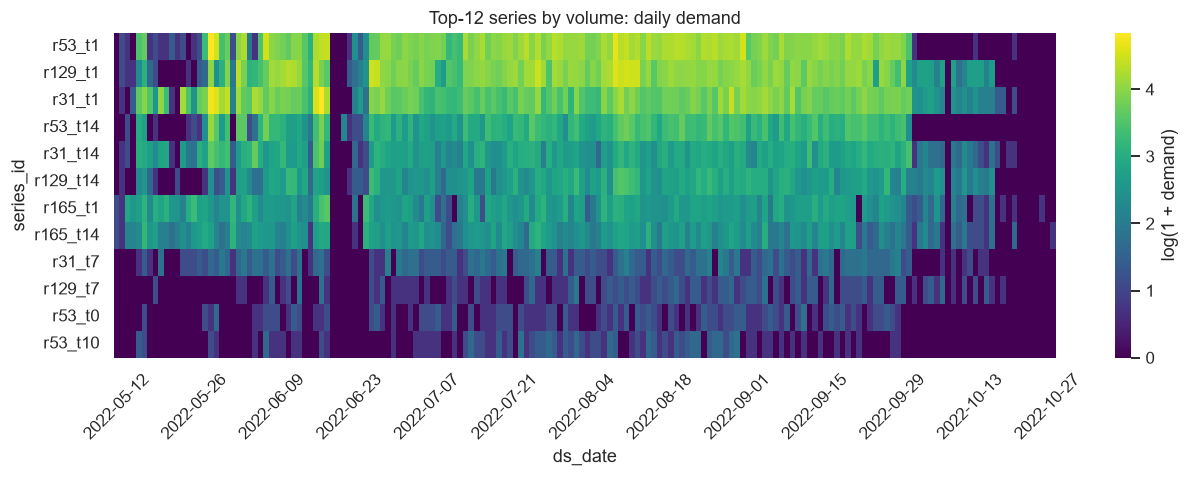

In [17]:
inStable = panel[panel["in_stable_period"]]
perSeries = pd.DataFrame({
    "totalOrders": panel.groupby("series_id")["demand"].sum(),
    "stableMean": inStable.groupby("series_id")["demand"].mean().round(2),
    "stableZeroShare": inStable.groupby("series_id")["demand"].apply(lambda s: (s == 0).mean()).round(3),
}).sort_values("totalOrders", ascending=False)
display(perSeries.head(12))
for t in (1.0, 3.0, 10.0):
    k = perSeries["stableMean"] >= t
    print(f"series with stable-window mean >= {t:>4} orders/day: {int(k.sum()):>2} of {nSeries}, covering {perSeries.loc[k, 'totalOrders'].sum() / perSeries['totalOrders'].sum():.1%} of orders")

top = perSeries.head(12).index
heat = panel[panel["series_id"].isin(top)].pivot(index="series_id", columns=dateCol, values="demand").loc[top]
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(np.log1p(heat), cmap="viridis", cbar_kws={"label": "log(1 + demand)"}, ax=ax, xticklabels=14)
ax.set_xticklabels([d.get_text()[:10] for d in ax.get_xticklabels()], rotation=45)
ax.set_title("Top-12 series by volume: daily demand")
saveFigure("panel_heatmap_top12")

count    1259.0
mean       24.9
std        56.2
min         1.0
25%         2.0
50%         7.0
75%        24.0
90%        61.2
99%       257.1
max       846.0
AOIs with >=  10 orders:  556 covering 92.7% of orders
AOIs with >=  30 orders:  270 covering 76.6% of orders
AOIs with >= 100 orders:   59 covering 39.7% of orders


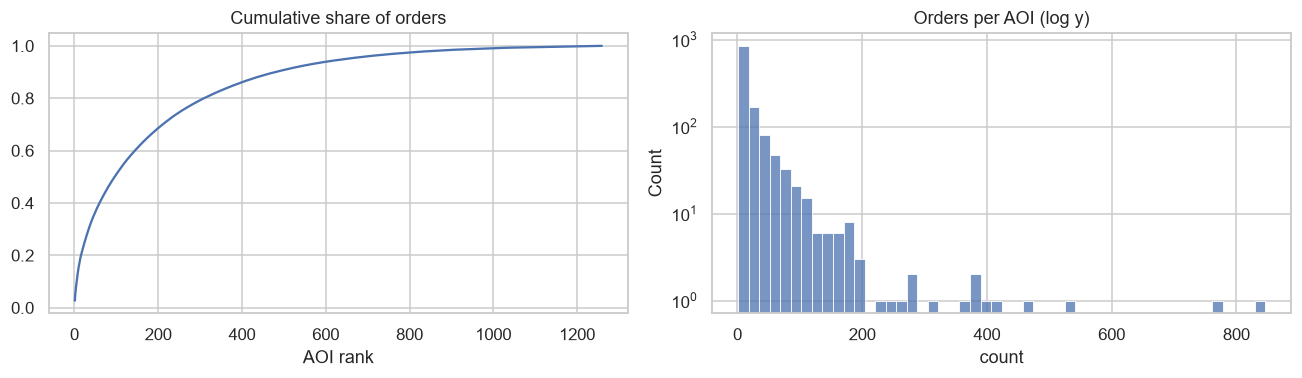

AOIs appearing in more than one region: 13


,aoi_id,region_id,n_regions,n_orders
1,94,31,2,4
49,2796,129,2,16
94,5314,129,2,14
111,6301,31,2,2
328,16176,129,2,31
332,16247,31,2,2
532,25621,129,2,6
579,27457,53,2,12
606,28865,129,2,19
734,35294,129,2,25


couriers per AOI: {'count': 1259.0, 'mean': 1.72, 'std': 1.07, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 8.0}
AOIs per courier: {'count': 57.0, 'mean': 37.9, 'std': 46.9, 'min': 1.0, '25%': 6.0, '50%': 16.0, '75%': 59.0, 'max': 231.0}


In [18]:
# Concentration of orders over AOIs and the AOI-region relationship
ordersPerAoi = orders["aoi_id"].value_counts()
print(ordersPerAoi.describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_string())
for t in (10, 30, 100):
    big = ordersPerAoi >= t
    print(f"AOIs with >= {t:>3} orders: {int(big.sum()):>4} covering {ordersPerAoi[big].sum() / len(orders):.1%} of orders")
cum = ordersPerAoi.sort_values(ascending=False).cumsum() / len(orders)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(np.arange(1, len(cum) + 1), cum.values); ax[0].set_xlabel("AOI rank"); ax[0].set_title("Cumulative share of orders")
sns.histplot(ordersPerAoi, bins=50, ax=ax[1]); ax[1].set_yscale("log"); ax[1].set_title("Orders per AOI (log y)")
saveFigure("aoi_concentration")

print("AOIs appearing in more than one region:", int(lookup["ambiguous_region"].sum()))
display(lookup.loc[lookup["ambiguous_region"], ["aoi_id", "region_id", "n_regions", "n_orders"]])
print("couriers per AOI:", orders.groupby("aoi_id")["courier_id"].nunique().describe().round(2).to_dict())
print("AOIs per courier:", orders.groupby("courier_id")["aoi_id"].nunique().describe().round(1).to_dict())

## 7. Phân bố không gian của điểm tiếp nhận

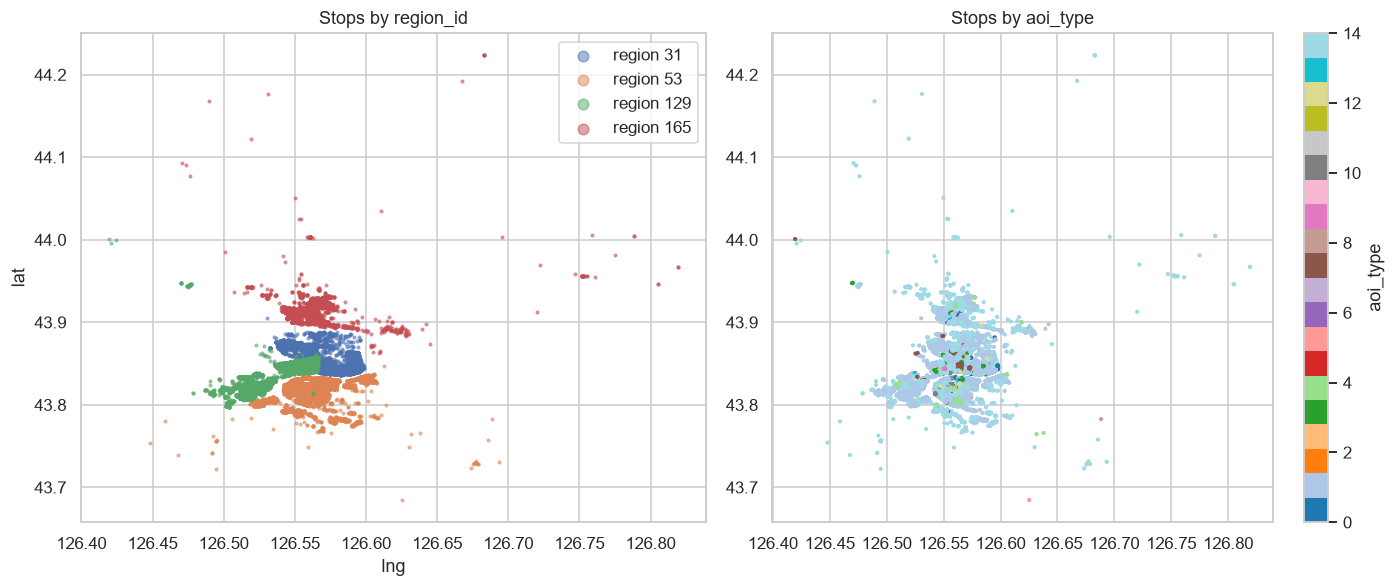

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for r, g in orders.groupby("region_id"):
    ax[0].scatter(g["lng"], g["lat"], s=3, label=f"region {r}", alpha=.5)
ax[0].legend(markerscale=4); ax[0].set_title("Stops by region_id"); ax[0].set_xlabel("lng"); ax[0].set_ylabel("lat")
sc = ax[1].scatter(orders["lng"], orders["lat"], c=orders["aoi_type"], s=3, cmap="tab20"); ax[1].set_title("Stops by aoi_type")
plt.colorbar(sc, ax=ax[1], label="aoi_type")
saveFigure("spatial_scatter")

In [20]:
# Descriptive accept-GPS centres only; routing uses one common depot fitted on train.
acc = orders.dropna(subset=["accept_gps_lng", "accept_gps_lat"]).query("not flag_invalid_gps").copy()
centre = acc.groupby("region_id")[["accept_gps_lng", "accept_gps_lat"]].median()
centre["spreadP90_m"] = acc.groupby("region_id").apply(
    lambda g: np.percentile(haversineMeters(g["accept_gps_lng"], g["accept_gps_lat"],
                                           g["accept_gps_lng"].median(), g["accept_gps_lat"].median()), 90))
display(centre.round(5))
acc["acceptToStop_km"] = haversineMeters(acc["accept_gps_lng"], acc["accept_gps_lat"], acc["lng"], acc["lat"]) / 1000
dg = haversineMeters(orders["delivery_gps_lng"], orders["delivery_gps_lat"], orders["lng"], orders["lat"])
dg = pd.Series(dg).where(~orders["flag_invalid_gps"].values)
print("accept GPS -> stop (km):", acc["acceptToStop_km"].describe().round(2).to_dict())
print("delivery GPS -> stop (m):", dg.describe().round(0).to_dict())
print("share of delivery GPS within 100 m of the stop:", round((dg.dropna() <= 100).mean(), 3))

,accept_gps_lng,accept_gps_lat,spreadP90_m
region_id,,,
31,126.56610,43.87095,34.71770
53,126.56690,43.81212,31.96713
129,126.54449,43.85022,23.78377
165,126.58469,43.89469,16.94578


accept GPS -> stop (km): {'count': 30442.0, 'mean': 2.43, 'std': 1.52, 'min': 0.0, '25%': 1.33, '50%': 2.28, '75%': 3.36, 'max': 37.39}
delivery GPS -> stop (m): {'count': 31397.0, 'mean': 319.0, 'std': 1761.0, 'min': 0.0, '25%': 32.0, '50%': 64.0, '75%': 170.0, 'max': 156106.0}
share of delivery GPS within 100 m of the stop: 0.625


## 8. Kết luận

## Kết luận

**Dữ liệu.** Tệp có 31.415 đơn, 57 shipper, 4 `region_id`, 1.259 AOI và 14 `aoi_type`, trùng với thống kê công bố của bộ dữ liệu (57 shipper, thời gian giao trung bình 203 phút, 16,3 đơn/shipper/ngày). Không có `order_id` trùng, `city` chỉ nhận giá trị Jilin, `ds` luôn bằng ngày nhận đơn nên đại lượng dự báo là số đơn được nhận mỗi ngày.

**Chất lượng và làm sạch.** Tệp gốc được giữ nguyên. Tập phân tích loại 8 đơn có thời gian giao trên 24 giờ (lưu trong `excluded_rows.csv`), còn 31.407 đơn. Các cờ còn lại chỉ đánh dấu, không loại: 955 đơn thiếu `accept_gps` (94,1% thuộc 5 shipper), 50 đơn có thời gian giao bằng 0, 10 đơn có tọa độ gần (0,0) được đặt về NaN, 19 đơn giao sang ngày hôm sau.

**Tính ổn định.** Số đơn trung bình mỗi ngày là 109 (tháng 5), 191, 216, 269, 247, rồi 39 (tháng 10). Phát hiện điểm gãy trên số shipper hoạt động cho ra hai đoạn chính: 27/6–2/10 (98 ngày; 13,0 shipper và 243,5 đơn/ngày) và 3/10–28/10 (3,0 shipper và 26,8 đơn/ngày). Thành phần số shipper hoạt động chiếm khoảng 67% biến động log của số đơn quan sát; thành phần còn lại là năng suất tính bằng tổng đơn chia tổng lượt shipper hoạt động theo ngày. Đây là đẳng thức kế toán mô tả mẫu quan sát, không phải tỷ lệ nguyên nhân gây giảm nhu cầu toàn thành phố. Tài liệu bộ dữ liệu không nêu nguyên nhân của đợt giảm này, nên nguyên nhân không được suy ra. Cửa sổ 27/6–2/10 được dùng làm cửa sổ chính; toàn bộ 12/5–28/10 được giữ làm kịch bản độ nhạy. Danh sách ngày không quan sát được đọc trực tiếp từ `panel_audit.json` và hiển thị ở cuối notebook; không mặc định các ngày này có nhu cầu thực bằng 0.

**Mức tổng hợp.** Cấp AOI có 90,0% ô (AOI × ngày) bằng 0, 0,15 đơn/AOI/ngày và hệ số tự tương quan bậc 1 (đã trừ trung bình từng chuỗi) bằng 0,28: tín hiệu quá thưa để dự báo trực tiếp. Cấp `region_id × aoi_type` có 41 chuỗi, 4,51 đơn/chuỗi/ngày, 64,8% ô bằng 0 (56,3% trong cửa sổ chính) và tự tương quan bậc 1 bằng 0,72 trên toàn kỳ (0,40 trong cửa sổ chính). Trong cửa sổ chính, 13 chuỗi chứa 97,0% số đơn và 8 chuỗi lớn nhất chứa 93,5%. Đơn vị dự báo là `region_id × aoi_type`; nút của bài toán CVRP là AOI.

**Không gian và kho xuất phát.** Tâm GPS tiếp nhận của từng region là thống kê mô tả về phân bố không gian của điểm tiếp nhận; không dùng làm vị trí kho. Theo v4, hệ thống dùng một depot chung, xác định riêng bằng dữ liệu train ở bước chuẩn bị định tuyến. 13 AOI xuất hiện ở hơn một `region_id` (chủ yếu rất ít đơn, riêng AOI 53702 có 771 đơn); nhãn `region_id` mô tả của AOI là giá trị xuất hiện nhiều nhất, còn `aoi_region_daily.csv` giữ nguyên `region_id` quan sát của từng đơn nên tổng đơn không bị dịch chuyển. Dữ liệu không chứa tải trọng hay thể tích đơn, nên nhu cầu trong CVRP là số đơn.

**Giới hạn.** Năm 2022 chỉ là quy ước kỹ thuật vì tệp không ghi năm, do đó các đặc trưng thứ trong tuần không phải là kết luận thực nghiệm. Việc chọn cửa sổ, việc loại 8 đơn trên 24 giờ và danh mục AOI lấy từ toàn kỳ đều dựa trên toàn bộ dữ liệu quan sát được, nên kết quả mang tính hồi cứu.

### Ngày không quan sát theo audit

Tương quan ở lag 7 yếu trong EDA; điều này chưa đủ để kết luận nhóm đặc trưng thứ trong tuần không hữu ích. Đặc trưng này được giữ làm ứng viên và đánh giá bằng mô hình và ablation ở RQ2.

In [21]:
from IPython.display import Markdown
from src.audit_reporting import loadUnobservedSummary
auditPath = config.PANEL_AUDIT_FILE
unobservedSummary = loadUnobservedSummary(auditPath)
display(Markdown(unobservedSummary['markdown']))

Có **7** ngày không quan sát: 2022-06-20, 2022-06-21, 2022-10-09, 2022-10-23, 2022-10-24, 2022-10-25, 2022-10-27.